In [2]:
import matplotlib.pyplot as plt
import numpy as np
import math

In [4]:
def memory_required(width, graph_size, LUT_SIZE):
    
    a = 2**width
    return graph_size * a + 20 * graph_size + 2 * LUT_SIZE


memory_required(4, 800, 2048)

32896

# Simulation analysis

In [29]:
import os 
import pandas as pd 

MT = os.path.join("..", "python_code", "runs", "iter=1e8_PC", "LFSR_8bit_UNITS=25_N=800", "logs")


def get_data(folder):
    res = []

    for file in os.listdir(folder):
        
        full_path = os.path.join(folder, file)
        if os.path.isfile(full_path):
            
            df = pd.read_csv(full_path)
            
            res.append(np.max(df["best_maxcuts"]))
    
    return np.array(res)        


df = get_data(MT)

# sort and take 20 best solutions (however I manually checked whether the solutions actually finished : some of them were killed by the OS for some reason)
df = np.sort(df)
df = df[0:20]

avg_distance = np.mean(3050-df)
best_solution = np.max(df)
consistency = np.sum((df == best_solution))

print(f"avg_distance={avg_distance}, best_solution={best_solution}, consistency={consistency}/{len(df)}({consistency/len(df) * 100 }%)")

avg_distance=1.2, best_solution=3049.0, consistency=19/20(95.0%)


# Make plot for results

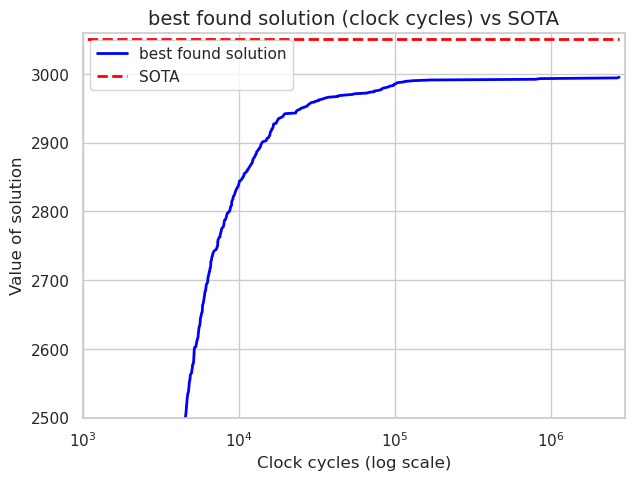

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data from the file
with open("current_best.txt") as f:
    lines = f.readlines()
    lines = [line.strip() for line in lines]
    lines = [line for line in lines if len(line) > 0]

    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip() )] for line in lines]

el = np.array(kv)

# Initialize a seaborn theme for better aesthetics
sns.set(style="whitegrid")

# Create a figure and axis
plt.figure(figsize=(7, 5))

# Plot the data
plt.plot(el[:,0], el[:,1], label="best found solution", color='blue', linewidth=2)

# Plot the SOTA line
plt.plot([min(el[:,0]), max(el[:,0])], [3050, 3050], label="SOTA", linestyle='--', color='red', linewidth=2)

# Zoom in on the region of interest and set log scale on x-axis
plt.xlim(1e3, 3e6)
plt.xscale("log")
plt.ylim(2500, 3060)

# Add labels and title
plt.xlabel("Clock cycles (log scale)", fontsize=12)
plt.ylabel("Value of solution", fontsize=12)
plt.title("best found solution (clock cycles) vs SOTA", fontsize=14)

# Add a legend
plt.legend()

# Display the plot
plt.show()

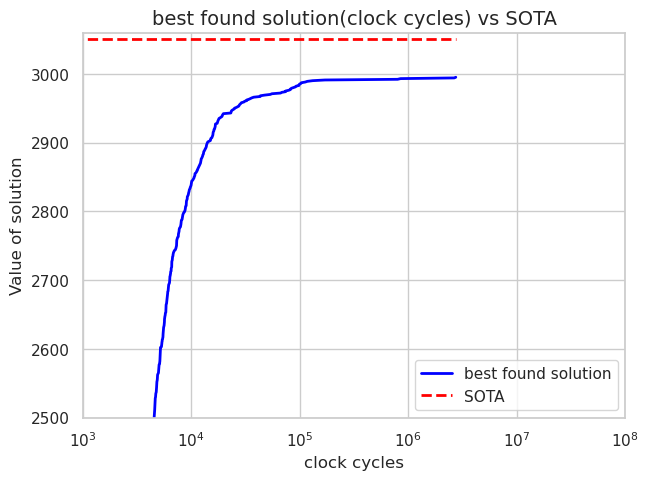

In [15]:
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data from the file
with open("current_best.txt") as f:
    lines = f.readlines()
    lines = [line.strip() for line in lines]
    lines = [line for line in lines if len(line) > 0]

    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip() )] for line in lines]

el = np.array(kv)

# Initialize a seaborn theme for better aesthetics
sns.set(style="whitegrid")

# Create a figure and axis
plt.figure(figsize=(7, 5))

# Plot the data
plt.plot(el[:,0], el[:,1], label="best found solution", color='blue', linewidth=2)

# Plot the SOTA line
plt.plot([min(el[:,0]), max(el[:,0])], [3050, 3050], label="SOTA", linestyle='--', color='red', linewidth=2)

# Zoom in on the region of interest
plt.ylim(2500, 3060)
plt.xlim(1e4, 2e6)
plt.xscale("log")

# Add labels and title
plt.xlabel("clock cycles", fontsize=12)
plt.ylabel("Value of solution", fontsize=12)
plt.title("best found solution(clock cycles) vs SOTA", fontsize=14)

# Get the current x-ticks
xticks = plt.gca().get_xticks()

# Set the new x-ticks with the last step included
plt.xticks(xticks)

# Add a legend
plt.legend()

plt.savefig("current_best.png")

# Display the plot
plt.show()